In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score)

from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

#load the uploaded dataset
df = pd.read_csv("/content/Wholesale customers data - Wholesale customers data.csv")

In [ ]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [ ]:
df.shape

(440, 8)

In [ ]:
df.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [ ]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = df[features].copy()

display(X.head())

print("Number of records used for clustering:", len(X))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Number of records used for clustering: 440


In [ ]:
#Standardize the six spending features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
#Convert scaled valued into a DataFrame for easier inspection

X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X.index)

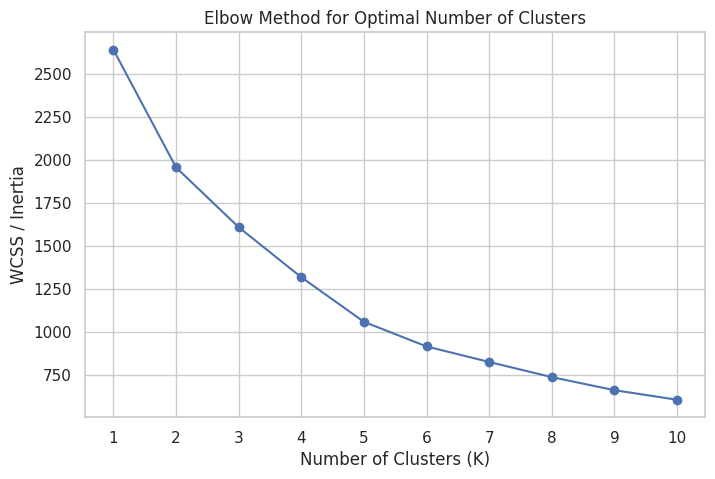

In [ ]:
#Calculate WCSS (Within-Cluster Sum of Squares)

wcss = []
k_values = range(1,11)

for k in k_values:
    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

#Plot the elbow curve
plt.figure(figsize=(8,5))
plt.plot(list(k_values),wcss,marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
#Calculate silhouette scores to support the elbow decision

silhouette_values = []

for k in range(2,11):
    model = KMeans(n_clusters = k, random_state=42, n_init = 10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "Number of Clusters" : list(range(2,11)),
    "Silhouette Score" : silhouette_values
})

display(silhouette_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [ ]:
#Suggested K based on the highest silhouette score

suggested_k = int(
    silhouette_table.loc[silhouette_table["Silhouette Score"].idxmax(), "Number of Clusters"])
print("K suggested by the highest silhouette score:", suggested_k)

K suggested by the highest silhouette score: 3


In [ ]:
K = suggested_k

#Build and train the K-Means model
kmeans_model = KMeans(n_clusters = K, random_state = 42, n_init = 10)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [ ]:
#Add cluster labels to a copy of the original dataset

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("K-Means clustering completed.")
print("\nNumber of customers in each cluster:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\nSample records with cluster labels:")
display(df_kmeans.head())

K-Means clustering completed.

Number of customers in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [ ]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=K,
    linkage="ward",
    metric="euclidean"
)
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

In [ ]:
df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed.")
print("\nNumber of customers in each cluster:")
print(df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index())

print("\nSample records with cluster labels:")
display(df_hierarchical.head())

Hierarchical clustering completed.

Number of customers in each cluster:
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64

Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


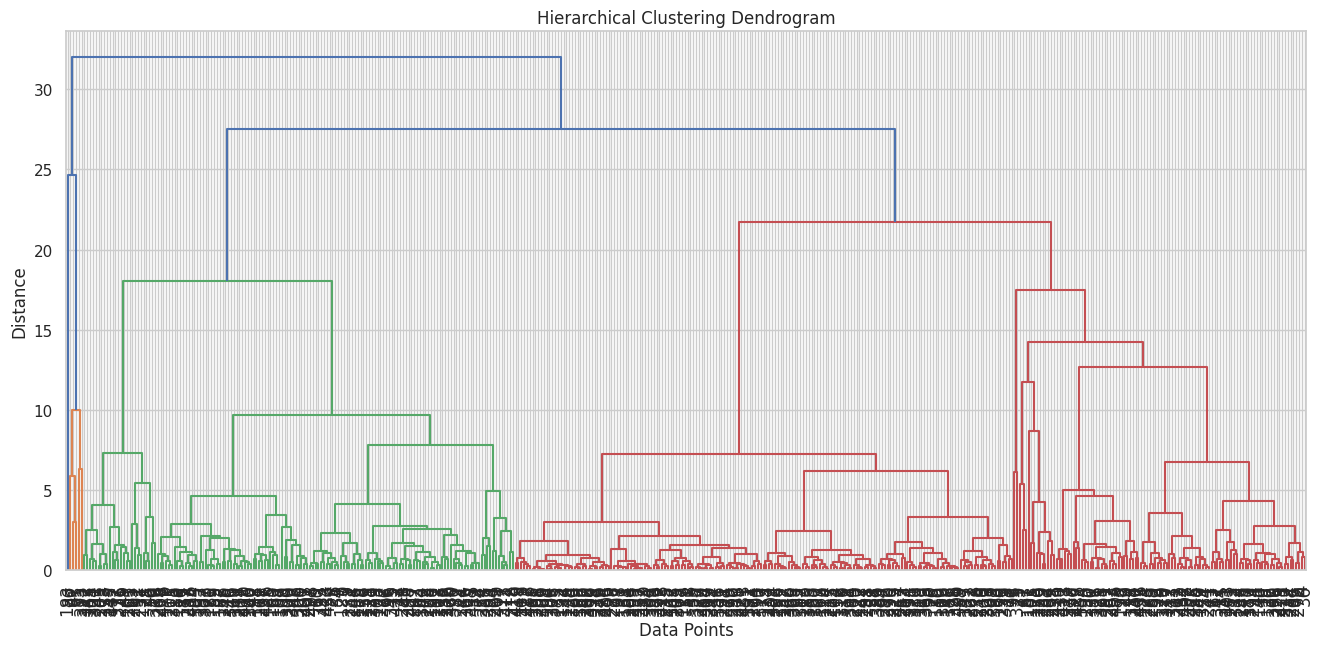

In [ ]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(16,7))
dendrogram(Z, leaf_rotation=90, leaf_font_size=12)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

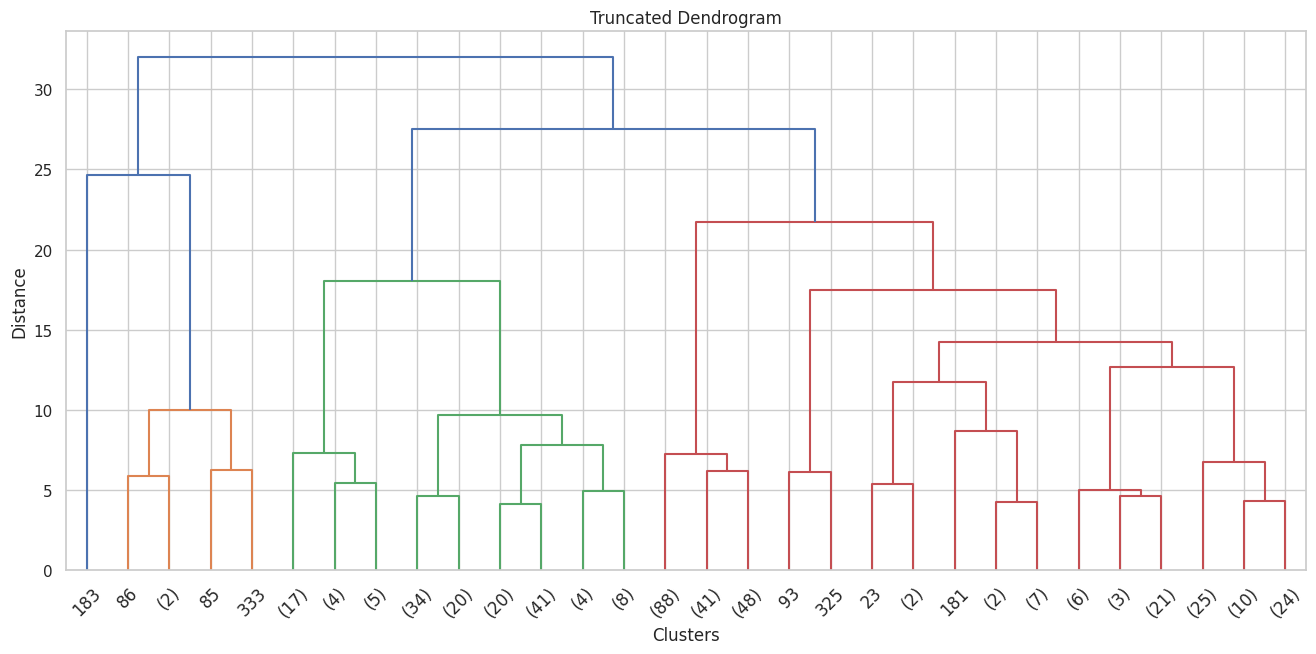

In [ ]:
plt.figure(figsize=(16,7))
dendrogram(Z,truncate_mode="lastp",p=30, leaf_rotation=45, leaf_font_size=12,show_leaf_counts=True)
plt.title("Truncated Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.show

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "variance explained by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100,2),"%"
)

plot_df = pd.DataFrame({"PC1": X_pca[:,0], "PC2": X_pca[:,1], "Kmeans_Cluster": kmeans_labels.astype(str),
                        "Hierarchical_Cluster": hierarchical_labels.astype(str)})


variance explained by the two PCA components: 72.46 %


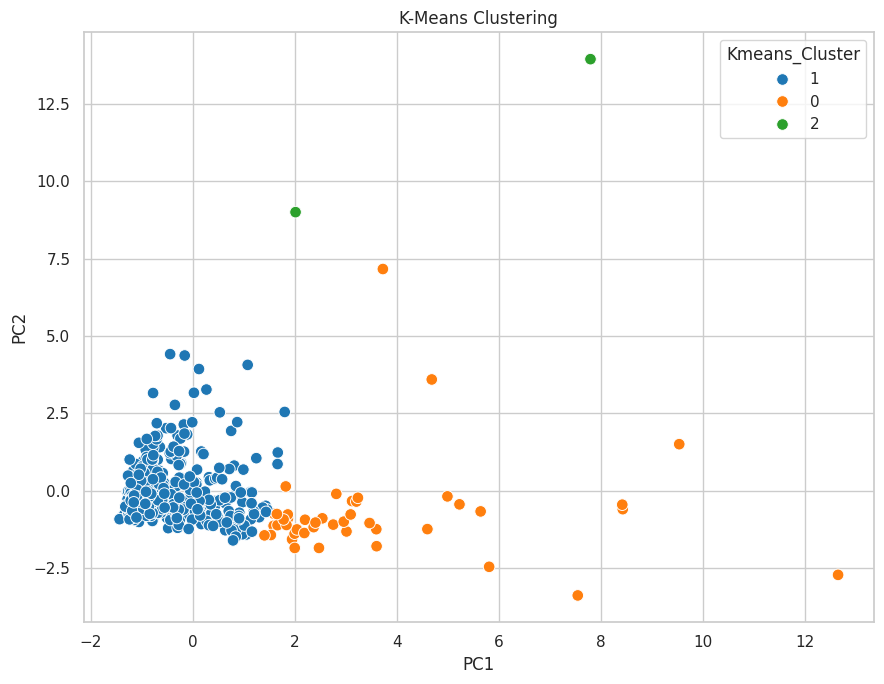

In [ ]:
plt.figure(figsize=(9,7))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Kmeans_Cluster", palette="tab10", s=70)
plt.title("K-Means Clustering")

plt.tight_layout()
plt.show()

In [ ]:
def evaluate_clustering(X_data, labels, model_name):
  return {
      "Algorithm": model_name,
      "Silhouette Score": silhouette_score(X_data, labels),
      "No. of Clusters": len(np.unique(labels)),
      "Calinski-Harabasz Score": calinski_harabasz_score(X_data, labels),
      "Davies-Bouldin Score": davies_bouldin_score(X_data, labels),
  }

In [ ]:
cluster_sizes = pd.DataFrame({
    "K-Means": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Hierarchical": pd.Series(hierarchical_labels).value_counts().sort_index()
}).fillna(0).astype(int)

display(cluster_sizes)

,K-Means,Hierarchical
0,45,6
1,393,281
2,2,153


In [ ]:
kmeans_scores = pd.DataFrame([evaluate_clustering(X_scaled, kmeans_labels, "K-Means")])
hierarchical_scores = pd.DataFrame([evaluate_clustering(X_scaled, hierarchical_labels, "Hierarchical")])

# Combine them into a single evaluation table for easy comparison
evaluation_df = pd.concat([kmeans_scores, hierarchical_scores], ignore_index=True)
display(evaluation_df)

,Algorithm,Silhouette Score,No. of Clusters,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-Means,0.548287,3,140.135183,0.927935
1,Hierarchical,0.264609,3,111.151039,1.284521


In [ ]:
cluster_distribution = pd.DataFrame({
    "Customer Count": pd.Series(kmeans_labels).value_counts().sort_index()
})
cluster_distribution["Percentage"] = (cluster_distribution["Customer Count"] / len(df) * 100)

cluster_distribution

,Customer Count,Percentage
0,45,10.227273
1,393,89.318182
2,2,0.454545


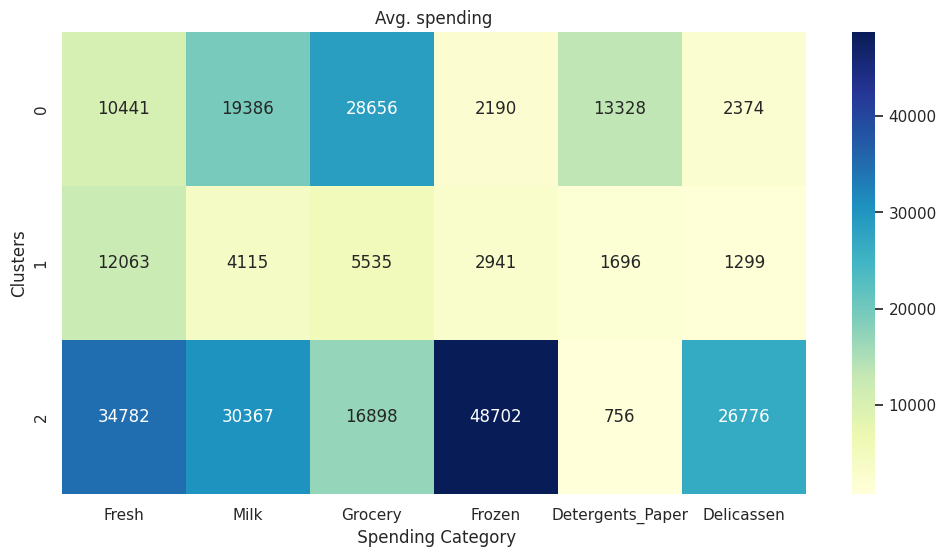

In [ ]:
# Calculate the mean spending of the original features for each K-Means cluster
kmeans_means = df_kmeans.groupby("KMeans_Cluster")[features].mean()

plt.figure(figsize=(12, 6))

sns.heatmap(kmeans_means, annot=True, fmt=".0f", cmap="YlGnBu")

plt.title("Avg. spending")
plt.xlabel(" Spending Category")
plt.ylabel("Clusters")

plt.show()

In [ ]:
channel_mix = pd.crosstab(df["Channel"],kmeans_labels, normalize="columns")* 100

channel_mix.columns = [f"Cluster {c}" for c in channel_mix.columns]

print("Channel Mix by Cluster:")
display(channel_mix.round(2))

Channel Mix by Cluster:


,Cluster 0,Cluster 1,Cluster 2
Channel,,,
1,2.22,75.06,100.0
2,97.78,24.94,0.0
